# Active Future Labs — Temperature Trend Analysis
**NASA Space Apps Challenge 2026**

## 1. Data Collection and Preparation

### Objective
Retrieve historical environmental measurements from the NASA POWER API and prepare a structured dataset for statistical analysis.

### Dataset
- Source: NASA POWER Monthly API
- Period: January 2000 – December 2024
- Frequency: Monthly
- Locations: Central Amazon, Interior Alaska, Southeast England and Western Sahel

### Environmental Variables
- T2M: 2-metre air temperature (°C)
- PRECTOTCORR: Corrected precipitation (mm/day)
- RH2M: Relative humidity (%)
- GWETTOP: Surface soil wetness (0–1)

The data is retrieved programmatically using Python's requests library and organised into a Pandas DataFrame.

Each location represents a selected geographical coordinate rather than an average across an entire region.

### Data Retrieval

The next cell requests NASA POWER monthly data at four representative grid locations.

In [ ]:
import requests
import pandas as pd
import numpy as np

# Representative coordinates (latitude, longitude)
locations = {
    "Central Amazon": (-3.10, -60.02),
    "Western Sahel": (13.52, 2.10),
    "Southeast England": (51.51, -0.13),
    "Interior Alaska": (64.84, -147.72)
}

variables = ["T2M", "PRECTOTCORR", "RH2M", "GWETTOP"]

url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

all_records = []

for region, (lat, lon) in locations.items():
    params = {
        "parameters": ",".join(variables),
        "community": "AG",
        "latitude": lat,
        "longitude": lon,
        "start": 2000,
        "end": 2024,
        "format": "JSON"
    }

    response = requests.get(url, params=params, timeout=120)
    response.raise_for_status()

    values = response.json()["properties"]["parameter"]

    for date in sorted(values["T2M"]):
        if len(date) != 6 or not date.isdigit():
            continue
        if not 1 <= int(date[-2:]) <= 12:
            continue

        row = {
            "region": region,
            "date": pd.to_datetime(date, format="%Y%m"),
            "latitude": lat,
            "longitude": lon
        }

        for var in variables:
            row[var] = values[var].get(date, np.nan)

        all_records.append(row)

df = pd.DataFrame(all_records)
df[variables] = df[variables].replace(-999, np.nan)
df = df.sort_values(["region", "date"]).reset_index(drop=True)

print("Rows:", len(df))
print("\nObservations by region:")
print(df.groupby("region").size())
print("\nMissing values:")
print(df[variables].isna().sum())

display(df.head(12))


Rows: 1200

Observations by region:
region
Central Amazon       300
Interior Alaska      300
Southeast England    300
Western Sahel        300
dtype: int64

Missing values:
T2M            0
PRECTOTCORR    0
RH2M           0
GWETTOP        0
dtype: int64


,region,date,latitude,longitude,T2M,PRECTOTCORR,RH2M,GWETTOP
0,Central Amazon,2000-01-01,-3.1,-60.02,25.62,9.20,87.08,0.80
1,Central Amazon,2000-02-01,-3.1,-60.02,25.58,9.74,88.11,0.88
2,Central Amazon,2000-03-01,-3.1,-60.02,25.59,12.36,86.95,0.94
3,Central Amazon,2000-04-01,-3.1,-60.02,25.61,11.97,87.00,0.95
4,Central Amazon,2000-05-01,-3.1,-60.02,25.82,7.80,87.71,0.94
5,Central Amazon,2000-06-01,-3.1,-60.02,25.48,4.62,89.49,0.90
6,Central Amazon,2000-07-01,-3.1,-60.02,25.03,4.15,87.66,0.87
7,Central Amazon,2000-08-01,-3.1,-60.02,26.10,2.59,85.21,0.80
8,Central Amazon,2000-09-01,-3.1,-60.02,26.64,5.23,83.20,0.72
9,Central Amazon,2000-10-01,-3.1,-60.02,27.09,3.40,81.83,0.70


### Data Quality Assessment

The API retrieval produced 1,200 monthly rows, 300 for each of the four sampled locations (2000–2024). All four environmental variables show zero missing values in the output.

These are **gridded estimates at sampled coordinates**, not station measurements or averages across entire named regions. The next cell applies a few additional basic validation checks.

In [ ]:
# Basic dataset checks; these do not replace scientific quality assurance
assert df["date"].min() == pd.Timestamp("2000-01-01")
assert df["date"].max() == pd.Timestamp("2024-12-01")
assert len(df) == 1200
assert not df.duplicated(["region", "date"]).any()
assert (df.groupby("region").size() == 300).all()
assert df[variables].notna().all().all()
assert df["T2M"].between(-90, 65).all()
assert df["RH2M"].between(0, 100).all()
assert df["PRECTOTCORR"].ge(0).all()
assert df["GWETTOP"].between(0, 1).all()
print("Basic completeness and range checks passed")

Basic completeness and range checks passed


## 2. Exploratory Data Analysis

### Objective
Investigate historical temperature variability across the four selected locations while reducing the influence of recurring seasonal patterns.

### Methodology
Monthly temperature anomalies are calculated by subtracting each location's average temperature for the corresponding calendar month over 2000–2024.

The monthly anomalies are then aggregated into annual averages.

This allows us to compare deviations from typical local temperature conditions without the seasonal cycle dominating the visualisation.

The resulting graph displays annual temperature anomalies for all four locations.

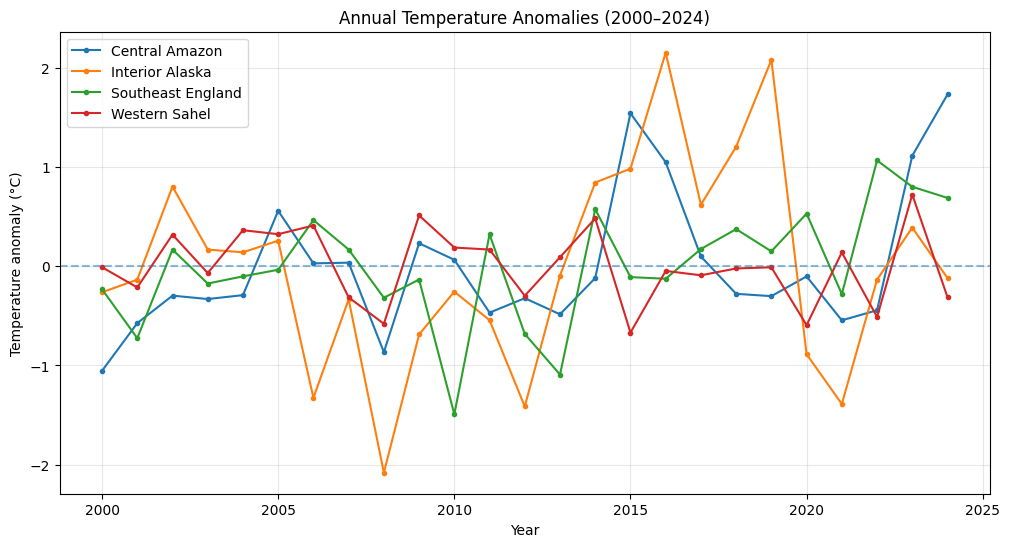

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Create a working copy
eda = df.copy()

eda["year"] = eda["date"].dt.year
eda["month"] = eda["date"].dt.month

# Remove each location's average seasonal cycle
eda["temp_anomaly"] = (
    eda["T2M"]
    - eda.groupby(["region", "month"])["T2M"]
         .transform("mean")
)

# Annual mean temperature anomalies
annual = (
    eda.groupby(["region", "year"], as_index=False)
       ["temp_anomaly"].mean()
)

# Visualise all four locations
plt.figure(figsize=(12, 6))

for region, group in annual.groupby("region"):
    plt.plot(
        group["year"],
        group["temp_anomaly"],
        marker="o",
        markersize=3,
        label=region
    )

plt.axhline(0, linestyle="--", alpha=0.5)

plt.title("Annual Temperature Anomalies (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Temperature anomaly (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Initial Observations

The visualisation reveals differences in annual temperature variability across the four geographical locations.

Some locations exhibit pronounced year-to-year fluctuations, while others show comparatively smaller deviations from their historical monthly averages.

The zero reference line represents each location's average temperature over the 2000–2024 baseline period.

Although the graph allows us to identify possible trends and unusual years, visual inspection alone cannot establish statistical significance.

Regression analysis is therefore required to quantify long-term changes and evaluate the associated uncertainty.

## 3. Statistical Trend Analysis

### Objective
Estimate long-term temperature changes and determine whether the observed trends are statistically distinguishable from zero.

### Model
Separate Ordinary Least Squares (OLS) regression models are fitted for each geographical location.

The models include:
- A continuous time variable to estimate temperature trends.
- Calendar-month controls to account for seasonality.
- HAC standard errors with 12 lags to account approximately for temporal autocorrelation and heteroskedasticity.

### Evaluation
For each location, the model calculates:
- Temperature trend (°C per decade)
- 95% confidence interval
- P-value for the time-trend coefficient

A p-value below 0.05 is initially treated as evidence of a statistically significant trend, before considering multiple-testing adjustments.

In [ ]:

import statsmodels.formula.api as smf

eda["time_years"] = (
    eda["year"] - 2000
    + (eda["month"] - 1) / 12
)

results = []

for region, group in eda.groupby("region"):

    model = smf.ols(
        "T2M ~ time_years + C(month)",
        data=group
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 12}
    )

    slope = model.params["time_years"] * 10
    ci = model.conf_int().loc["time_years"] * 10

    results.append({
        "Region": region,
        "Trend (°C/decade)": round(slope, 3),
        "CI lower": round(ci.iloc[0], 3),
        "CI upper": round(ci.iloc[1], 3),
        "P-value": round(
            model.pvalues["time_years"], 5
        )
    })

results_df = pd.DataFrame(results)

display(results_df)


,Region,Trend (°C/decade),CI lower,CI upper,P-value
0,Central Amazon,0.414,0.033,0.795,0.03317
1,Interior Alaska,0.256,-0.218,0.730,0.29034
2,Southeast England,0.349,0.130,0.567,0.00176
3,Western Sahel,-0.093,-0.335,0.148,0.44874


In [ ]:
from statsmodels.stats.multitest import multipletests

# Refit to retain full-precision p-values for multiple-testing adjustment
p_values = []
region_names = []
for region, group in eda.groupby("region"):
    fitted = smf.ols("T2M ~ time_years + C(month)", data=group).fit(
        cov_type="HAC", cov_kwds={"maxlags": 12}
    )
    region_names.append(region)
    p_values.append(float(fitted.pvalues["time_years"]))

significant, adjusted_p, _, _ = multipletests(
    p_values, alpha=0.05, method="fdr_bh"
)
fdr_results = pd.DataFrame({
    "Location": region_names,
    "Raw p-value": p_values,
    "BH-adjusted p-value": adjusted_p,
    "Significant (5% FDR)": significant,
})
display(fdr_results.round(5))

,Location,Raw p-value,BH-adjusted p-value,Significant (5% FDR)
0,Central Amazon,0.03317,0.06634,False
1,Interior Alaska,0.29034,0.38712,False
2,Southeast England,0.00176,0.00704,True
3,Western Sahel,0.44874,0.44874,False


### Interpretation

Seasonal OLS regression estimates positive 2000–2024 temperature trends in Central Amazon, Interior Alaska and Southeast England, and a small negative estimate in Western Sahel. At the **unadjusted** 5% level, Central Amazon and Southeast England have trends distinguishable from zero. After a **Benjamini–Hochberg correction for four tests**, only Southeast England remains significant at the 5% false-discovery-rate threshold. The previous code cell computes the adjusted p-values; run it in Colab to display them. Non-significant results do **not** prove an absence of temperature change.

### Limitations

- Each named location is one representative NASA POWER grid-point estimate, **not** a whole-region mean.
- Trend results depend on the 2000–2024 time window and assumed linear specification.
- Month indicators adjust the recurring seasonal mean. HAC standard errors with 12 lags address temporal dependence approximately; residual diagnostics and lag/period sensitivity checks remain necessary.
- Annual anomalies are relative to each location's own 2000–2024 monthly climatology.
- These models estimate past trends; they do not establish causation or make forecasts.

### Data Source and Acknowledgements

Data were retrieved using the **NASA Langley Research Center POWER Project Monthly Point API**, with the `AG` community and the exact coordinates specified in the acquisition code. The meteorological estimates are based on NASA data products including MERRA-2. Data were accessed on 14 November 2026. For formal submission, record the service/data version from the API metadata if available.

NASA POWER referencing guide: https://power.larc.nasa.gov/docs/referencing/

### Next Steps

Validate model diagnostics; assess period and HAC-lag sensitivity; apply suitably chosen methods to precipitation, humidity and soil wetness; integrate measured slopes, confidence intervals and adjusted p-values into the interactive dashboard.